# Fine-tuning de un Vision Transformer (ViT) para clasificar residuos

**Proyecto 4 – Detección de residuos y clasificación de basura** · Sistemas de Inteligencia Artificial

Este notebook toma un **Transformer pre-entrenado** (`google/vit-base-patch16-224-in21k`, entrenado por Google en ImageNet-21k con 14 millones de imágenes) y lo **afina (fine-tuning)** para clasificar residuos en 6 clases:

| Clase | Tipo | Caneca (Res. 2184/2019) |
|---|---|---|
| Plástico, Papel, Cartón, Vidrio, Metal | Inorgánico (aprovechable) | Blanca |
| Orgánico | Orgánico | Verde |

### ¿Por qué un Transformer para imágenes?
El ViT aplica la misma idea del artículo *"Attention is All You Need"* (2017) que vimos en NLP:
la imagen de 224×224 se parte en **196 parches de 16×16**, y cada parche se trata como si fuera un **token**
(como una palabra en una frase). Se le suma un *embedding* de posición y se agrega un token especial `[CLS]`
(igual que en **BERT**). Luego, el **encoder** calcula *self-attention*:

$$\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

Así, cada parche "mira" a todos los demás parches, y el vector final del token `[CLS]` se usa para clasificar.
Es una arquitectura **solo-encoder**, igual que BERT, pero aplicada a imágenes.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, torch, matplotlib.pyplot as plt, seaborn as sns
from datasets import load_dataset
from transformers import ViTImageProcessor, ViTForImageClassification, TrainingArguments, Trainer
from torchvision import transforms as T
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from config import DATA_PROC, VIT_BASE, VIT_FINETUNED, CLASES, INFO_CLASES, RAIZ

OUT = RAIZ / 'outputs'; OUT.mkdir(exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

Dispositivo: cuda NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Dataset
Dataset público *Garbage Classification (12 clases)*. Las 12 clases originales se agrupan en 6 con `prepare_data.py` (se unen los 3 tipos de vidrio y *biological* pasa a ser *orgánico*), se balancean (máximo 1000 imágenes por clase) y se dividen en 70% entrenamiento, 15% validación y 15% prueba.

In [2]:
ds = load_dataset('imagefolder', data_dir=str(DATA_PROC))
labels = ds['train'].features['label'].names
assert labels == CLASES, labels
id2label = {i: l for i, l in enumerate(labels)}
label2id = {l: i for i, l in id2label.items()}
print(ds)
for split in ds:
    conteo = np.bincount(ds[split]['label'], minlength=len(labels))
    print(split, dict(zip(labels, conteo.tolist())))

Resolving data files:   0%|          | 0/3855 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/827 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/828 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 3855
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 827
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 828
    })
})
train {'carton': 623, 'metal': 538, 'organico': 689, 'papel': 700, 'plastico': 605, 'vidrio': 700}
validation {'carton': 134, 'metal': 115, 'organico': 148, 'papel': 150, 'plastico': 130, 'vidrio': 150}
test {'carton': 134, 'metal': 116, 'organico': 148, 'papel': 150, 'plastico': 130, 'vidrio': 150}


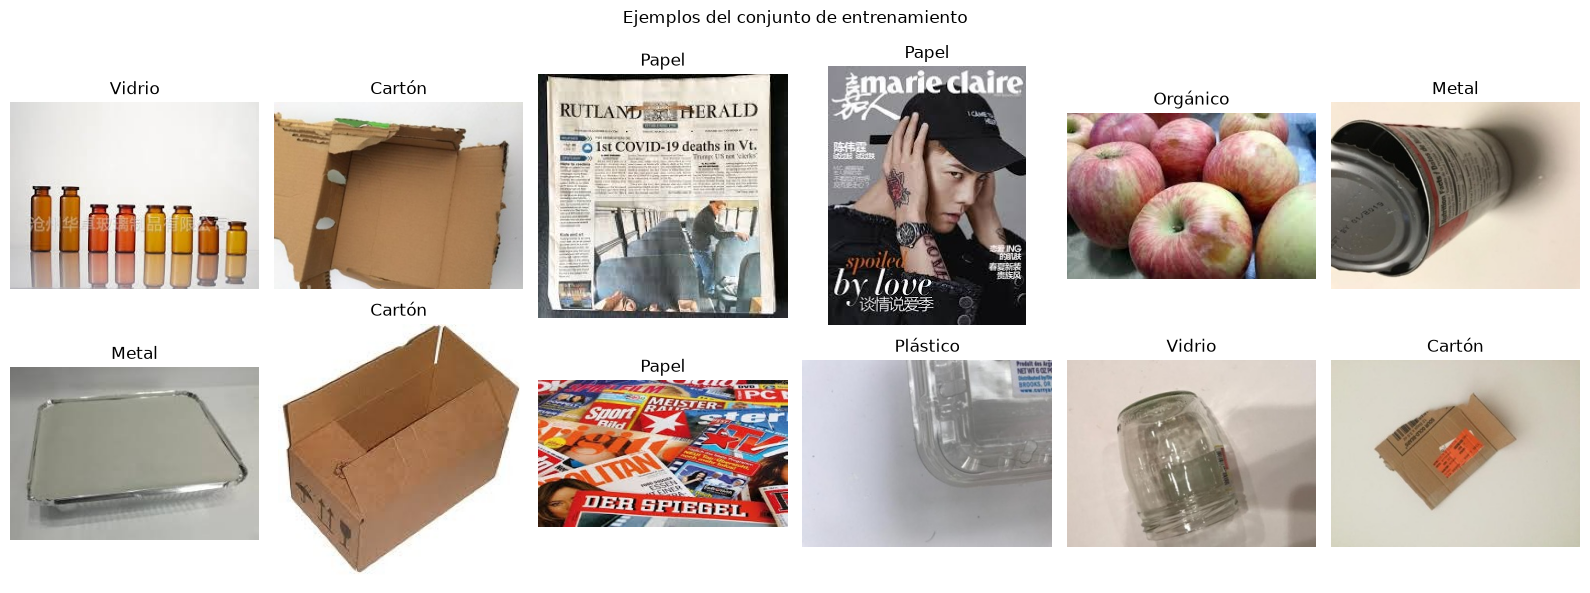

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
rng = np.random.default_rng(0)
for ax, i in zip(axes.flat, rng.choice(len(ds['train']), 12, replace=False)):
    ej = ds['train'][int(i)]
    ax.imshow(ej['image']); ax.set_title(INFO_CLASES[labels[ej['label']]]['nombre']); ax.axis('off')
plt.suptitle('Ejemplos del conjunto de entrenamiento'); plt.tight_layout()
plt.savefig(OUT / 'ejemplos_dataset.png', dpi=120); plt.show()

## 2. Pre-procesamiento y *data augmentation*
Se usa el `ViTImageProcessor` del modelo pre-entrenado (que define el tamaño y la normalización). En entrenamiento se aplican recortes, giros y cambios de color aleatorios para que el modelo generalice mejor.

In [4]:
processor = ViTImageProcessor.from_pretrained(VIT_BASE)
size = processor.size['height']
norm = T.Normalize(mean=processor.image_mean, std=processor.image_std)
tf_train = T.Compose([T.RandomResizedCrop(size, scale=(0.6, 1.0)), T.RandomHorizontalFlip(),
                      T.RandomRotation(15), T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor(), norm])
tf_eval = T.Compose([T.Resize(size), T.CenterCrop(size), T.ToTensor(), norm])

def aplicar(tf):
    def f(batch):
        batch['pixel_values'] = [tf(im.convert('RGB')) for im in batch['image']]
        return batch
    return f

ds['train'].set_transform(aplicar(tf_train))
ds['validation'].set_transform(aplicar(tf_eval))
ds['test'].set_transform(aplicar(tf_eval))

def collate(batch):
    return {'pixel_values': torch.stack([b['pixel_values'] for b in batch]),
            'labels': torch.tensor([b['label'] for b in batch])}

## 3. Modelo pre-entrenado + nueva cabeza de clasificación
Se cargan los pesos pre-entrenados del encoder (12 capas, 12 cabezas de atención, 86M de parámetros) y se agrega una capa lineal nueva de 6 salidas.

In [5]:
model = ViTForImageClassification.from_pretrained(
    VIT_BASE, num_labels=len(labels), id2label=id2label, label2id=label2id, dtype=torch.float32)
total = sum(p.numel() for p in model.parameters())
print(f'Parámetros: {total/1e6:.1f} M | capas: {model.config.num_hidden_layers} | cabezas de atención: {model.config.num_attention_heads}')

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parámetros: 85.8 M | capas: 12 | cabezas de atención: 12


In [6]:
def metricas(p):
    pred = p.predictions.argmax(-1)
    return {'accuracy': accuracy_score(p.label_ids, pred),
            'f1_macro': f1_score(p.label_ids, pred, average='macro')}

args = TrainingArguments(
    output_dir=str(RAIZ / 'models' / 'checkpoints'),
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    num_train_epochs=5, learning_rate=5e-5, weight_decay=0.01, warmup_steps=0.1,
    lr_scheduler_type='cosine', fp16=(device == 'cuda'),
    eval_strategy='epoch', save_strategy='epoch', save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model='f1_macro',
    logging_steps=20, remove_unused_columns=False, dataloader_num_workers=0,
    report_to='none', seed=42)

trainer = Trainer(model=model, args=args, train_dataset=ds['train'], eval_dataset=ds['validation'],
                  data_collator=collate, compute_metrics=metricas)
resultado = trainer.train()
print(resultado)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.509832,0.449041,0.944377,0.942980
2,0.215707,0.214774,0.967352,0.966749
3,0.132141,0.166185,0.969770,0.969447
4,0.083485,0.149183,0.967352,0.966713
5,0.068367,0.152132,0.968561,0.967909


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

[transformers] There were unexpected keys in the checkpoint model loaded: ['vit.encoder.layer.0.attention.attention.key.bias', 'vit.encoder.layer.0.attention.attention.key.weight', 'vit.encoder.layer.0.attention.attention.query.bias', 'vit.encoder.layer.0.attention.attention.query.weight', 'vit.encoder.layer.0.attention.attention.value.bias', 'vit.encoder.layer.0.attention.attention.value.weight', 'vit.encoder.layer.0.attention.output.dense.bias', 'vit.encoder.layer.0.attention.output.dense.weight', 'vit.encoder.layer.0.intermediate.dense.bias', 'vit.encoder.layer.0.intermediate.dense.weight', 'vit.encoder.layer.0.layernorm_after.bias', 'vit.encoder.layer.0.layernorm_after.weight', 'vit.encoder.layer.0.layernorm_before.bias', 'vit.encoder.layer.0.layernorm_before.weight', 'vit.encoder.layer.0.output.dense.bias', 'vit.encoder.layer.0.output.dense.weight', 'vit.encoder.layer.1.attention.attention.key.bias', 'vit.encoder.layer.1.attention.attention.key.weight', 'vit.encoder.layer.1.attent

TrainOutput(global_step=605, training_loss=0.35299268729430583, metrics={'train_runtime': 320.2191, 'train_samples_per_second': 60.193, 'train_steps_per_second': 1.889, 'total_flos': 1.493711648561664e+18, 'train_loss': 0.35299268729430583, 'epoch': 5.0})


## 4. Curvas de entrenamiento

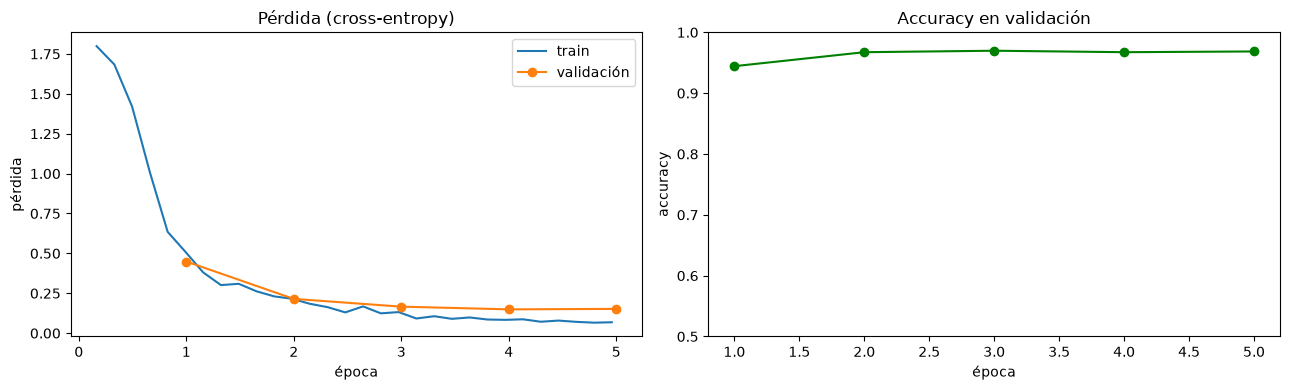

In [7]:
h = trainer.state.log_history
tr = [(x['epoch'], x['loss']) for x in h if 'loss' in x]
ev = [(x['epoch'], x['eval_loss'], x['eval_accuracy']) for x in h if 'eval_loss' in x]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(*zip(*tr), label='train'); a1.plot([e[0] for e in ev], [e[1] for e in ev], 'o-', label='validación')
a1.set_xlabel('época'); a1.set_ylabel('pérdida'); a1.legend(); a1.set_title('Pérdida (cross-entropy)')
a2.plot([e[0] for e in ev], [e[2] for e in ev], 'o-', color='green')
a2.set_xlabel('época'); a2.set_ylabel('accuracy'); a2.set_title('Accuracy en validación'); a2.set_ylim(0.5, 1)
plt.tight_layout(); plt.savefig(OUT / 'curvas_entrenamiento.png', dpi=120); plt.show()

## 5. Evaluación en el conjunto de prueba (imágenes nunca vistas)

Accuracy test: 0.9698 | F1 macro: 0.9689

              precision    recall  f1-score   support

      Cartón      1.000     0.963     0.981       134
       Metal      0.928     1.000     0.963       116
    Orgánico      0.993     0.993     0.993       148
       Papel      0.986     0.960     0.973       150
    Plástico      0.944     0.915     0.930       130
      Vidrio      0.961     0.987     0.974       150

    accuracy                          0.970       828
   macro avg      0.969     0.970     0.969       828
weighted avg      0.970     0.970     0.970       828



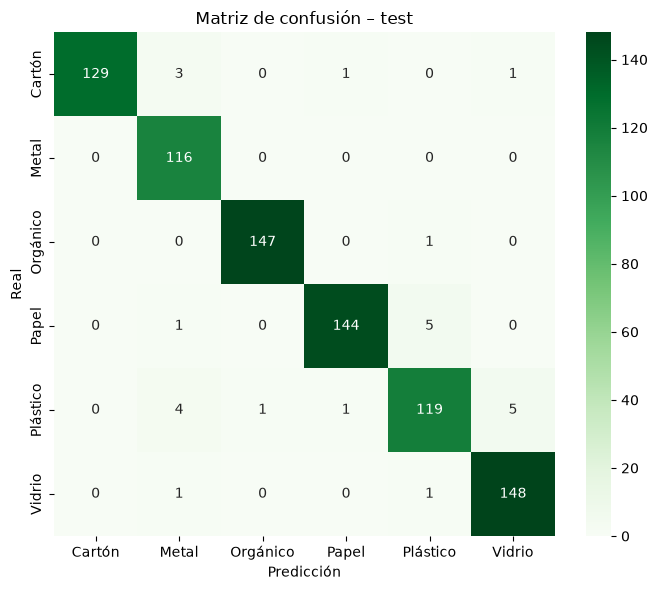

In [8]:
pred = trainer.predict(ds['test'])
y_true, y_pred = pred.label_ids, pred.predictions.argmax(-1)
nombres = [INFO_CLASES[l]['nombre'] for l in labels]
print(f"Accuracy test: {accuracy_score(y_true, y_pred):.4f} | F1 macro: {f1_score(y_true, y_pred, average='macro'):.4f}\n")
print(classification_report(y_true, y_pred, target_names=nombres, digits=3))
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=nombres, yticklabels=nombres)
plt.xlabel('Predicción'); plt.ylabel('Real'); plt.title('Matriz de confusión – test')
plt.tight_layout(); plt.savefig(OUT / 'matriz_confusion.png', dpi=120); plt.show()

## 6. Guardar el modelo afinado
El modelo queda guardado localmente y la aplicación lo usa sin ninguna API externa.

In [9]:
trainer.save_model(str(VIT_FINETUNED))
processor.save_pretrained(str(VIT_FINETUNED))
print('Guardado en', VIT_FINETUNED)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Guardado en C:\Users\DANILO MONTEZUMA\Desktop\Folders\8vo\SistemasIA\FINAL\models\vit-residuos


## 7. ¿Dónde "mira" el Transformer? – Mapa de atención
Se visualiza la atención del token `[CLS]` hacia los 196 parches, promediando todas las cabezas y combinando las 12 capas (*attention rollout*). Las zonas claras son las que más usó el modelo para decidir.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3855 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/827 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/828 [00:00<?, ?it/s]

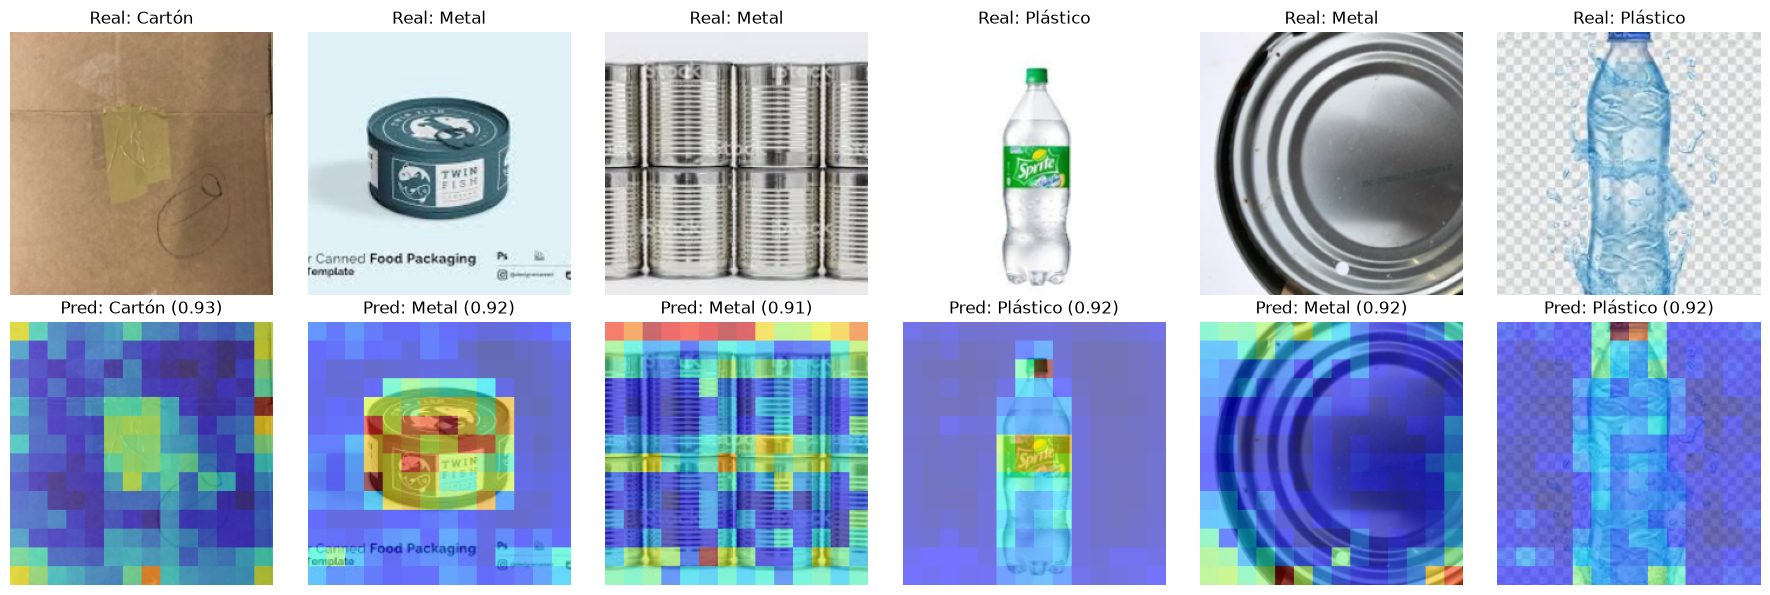

In [10]:
vis = ViTForImageClassification.from_pretrained(str(VIT_FINETUNED), attn_implementation='eager').to(device).eval()
test_raw = load_dataset('imagefolder', data_dir=str(DATA_PROC), split='test')

def rollout(atts):
    res = torch.eye(atts[0].size(-1), device=atts[0].device)
    for a in atts:
        a = a.mean(1)[0]
        a = a + torch.eye(a.size(-1), device=a.device); a = a / a.sum(-1, keepdim=True)
        res = a @ res
    m = res[0, 1:].reshape(14, 14).cpu().numpy()
    return (m - m.min()) / (m.max() - m.min())

rng = np.random.default_rng(3)
idx = rng.choice(len(test_raw), 6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for k, i in enumerate(idx):
    im = test_raw[int(i)]['image'].convert('RGB')
    x = tf_eval(im).unsqueeze(0).to(device)
    with torch.no_grad():
        out = vis(pixel_values=x, output_attentions=True)
    p = out.logits.softmax(-1)[0]; c = int(p.argmax())
    m = rollout(out.attentions)
    im224 = T.CenterCrop(224)(T.Resize(224)(im))
    axes[0, k].imshow(im224); axes[0, k].axis('off')
    axes[0, k].set_title(f"Real: {INFO_CLASES[labels[test_raw[int(i)]['label']]]['nombre']}")
    axes[1, k].imshow(im224); axes[1, k].imshow(np.kron(m, np.ones((16, 16))), alpha=0.55, cmap='jet'); axes[1, k].axis('off')
    axes[1, k].set_title(f"Pred: {INFO_CLASES[labels[c]]['nombre']} ({p[c]:.2f})")
plt.tight_layout(); plt.savefig(OUT / 'mapas_atencion.png', dpi=120); plt.show()